# Hit Song Science: experiments (BinarySVM / Pegasos, 80:20 split)

Target: **Popular** (`is_trending = 1`) vs **Not popular** (`is_trending = -1`). Metric: **accuracy**.
Model: `BinarySVM` (linear SVM trained with Pegasos), wrapped in `Standardized` so the scaler is
fitted on training data only. Data: `data/complete_only`. `duration_ms` is no longer used.

**Protocol for every scenario**
1. Split the dataset 80:20 (stratified, seed 42). The 20% test set is not touched until step 4.
2. Tune C ∈ {1e-3, 1e-2, 1e-1, 1} with 5-fold CV on the 80% training set. This notebook uses its own grid
   because Pegasos needs far more epochs for C > 1 (`config.C_GRID` goes up to 100).
3. **Choose** the best feature set / week by this CV accuracy.
4. Retrain on the full 80% with the best C and **report** accuracy on the 20% test set.

| Stage | Question | Data |
|---|---|---|
| 1 | Spotify vs MFCC vs both | `n1_all` |
| 2 | Best observation window: n1, n2, n3, n4, n8 | `nX_all`, best feature set |
| 3 | Does old data still predict new data? | `nX_old`, `nX_new` (best week), each split 80:20 |

Settings (feature lists, C grid, seed, split size) live in `config.py`; data helpers in `preprocessing.py`;
tuning, tables and plots in `evaluation.py`.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

from config import WEEKS, FEATURE_SETS, LABEL_NAMES, TEST_SIZE, SEED
from preprocessing import load_dataset, get_xy, stratified_train_test_split
from model import BinarySVM, Standardized
from evaluation import (tune_and_test, curve_table, summary_table, plot_c_curves, plot_results,
                        set_plot_style, check_accuracy, confusion_matrix, show_confusion_matrix)

set_plot_style()


C_GRID_PEGASOS = [1e-2, 1e-1, 1, 10, 100]  # config.C_GRID goes up to 100: too slow for Pegasos


def make_model(C):
    return Standardized(BinarySVM(C=C, random_state=SEED))


def split(df, features):
    X, y = get_xy(df, features)
    return stratified_train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)


def run(df, features, desc=""):
    # 80:20 split, tune C by CV on the 80%, retrain, score on the 20%
    X_train, X_test, y_train, y_test = split(df, features)
    return tune_and_test(make_model, X_train, y_train, X_test, y_test, desc=desc, C_grid=C_GRID_PEGASOS)


for name, features in FEATURE_SETS.items():
    print(f"{name}: {len(features)} features")

Spotify: 10 features
MFCC: 26 features
Spotify + MFCC: 36 features


## Data overview (`complete_only`)

In [2]:
overview = []
for week in WEEKS:
    for subset in ("all", "old", "new"):
        df = load_dataset(week, subset)
        n_test = sum(round(TEST_SIZE * n) for n in df["is_trending"].value_counts())
        overview.append({"week": f"n{week}", "subset": subset, "songs": len(df),
                         "Popular": int((df["is_trending"] == 1).sum()),
                         "Not popular": int((df["is_trending"] == -1).sum()),
                         "train (80%)": len(df) - n_test, "test (20%)": n_test})
display(pd.DataFrame(overview).set_index(["week", "subset"]))

songs  Popular  Not popular  train (80%)  test (20%)
week subset                                                      
n1   all      2448     1224         1224         1958         490
     old      1036      518          518          828         208
     new      1412      706          706         1130         282
n2   all      2174     1087         1087         1740         434
     old       962      481          481          770         192
     new      1212      606          606          970         242
n3   all      2030     1015         1015         1624         406
     old       910      455          455          728         182
     new      1120      560          560          896         224
n4   all      1902      951          951         1522         380
     old       838      419          419          670         168
     new      1064      532          532          852         212
n8   all      1588      794          794         1270         318
     old       720      360          360          576         144
     new       868      434          434          694         174

---
## Stage 1: Which features are best? (`n1_all`)

**Spotify** (10 features, without `duration_ms`), **MFCC** (26), **Spotify + MFCC** (36).


Spotify:   0%|          | 0/4 [00:00<?, ?it/s]


Spotify:  25%|██▌       | 1/4 [00:00<00:00,  3.21it/s]


Spotify:  50%|█████     | 2/4 [00:01<00:01,  1.79it/s]


Spotify:  75%|███████▌  | 3/4 [00:04<00:01,  1.72s/it]


Spotify: 100%|██████████| 4/4 [00:17<00:00,  6.14s/it]


MFCC:   0%|          | 0/4 [00:00<?, ?it/s]

... (7 outputs left out)


Spotify + MFCC:  75%|███████▌  | 3/4 [00:07<00:03,  3.06s/it]


Spotify + MFCC: 100%|██████████| 4/4 [00:46<00:00, 17.29s/it]

CV accuracy on the training set (mean ± std) per C   (* = best C)


,Spotify,MFCC,Spotify + MFCC
C,,,
0.001,0.573 ± 0.023,0.504 ± 0.015,0.602 ± 0.031
0.01,0.610 ± 0.018,0.524 ± 0.015 *,0.649 ± 0.025
0.1,0.620 ± 0.018,0.519 ± 0.025,0.661 ± 0.021 *
1,0.642 ± 0.015 *,0.519 ± 0.031,0.660 ± 0.014


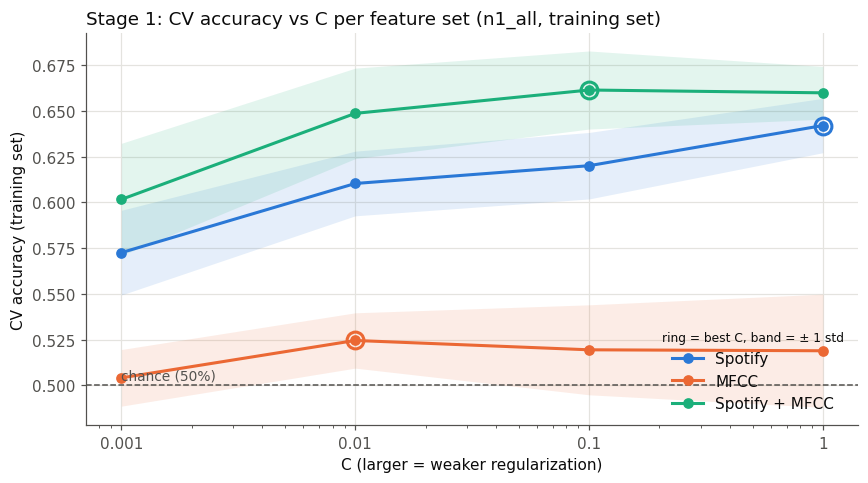

In [3]:
df_n1 = load_dataset(1, "all")
stage1 = {name: run(df_n1, features, desc=name) for name, features in FEATURE_SETS.items()}

print("CV accuracy on the training set (mean ± std) per C   (* = best C)")
display(curve_table({name: r["curve"] for name, r in stage1.items()}))
plot_c_curves({name: r["curve"] for name, r in stage1.items()},
              "Stage 1: CV accuracy vs C per feature set (n1_all, training set)")

,best C,CV accuracy,CV std,test accuracy,n features
scenario,,,,,
Spotify,1,0.6420,0.0148,0.6469,10
MFCC,0.01,0.5245,0.0151,0.5265,26
Spotify + MFCC,0.1,0.6614,0.0213,0.6592,36


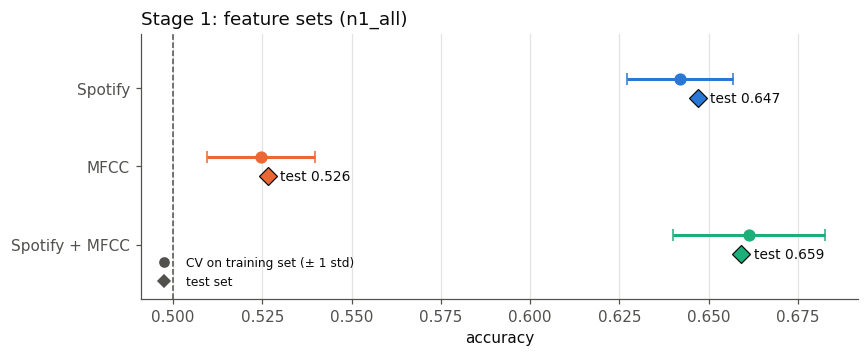

Best feature set (chosen by CV): Spotify + MFCC  |  CV 0.6614, test 0.6592, C = 0.1


In [4]:
stage1_summary = summary_table(stage1, {n: {"n features": len(f)} for n, f in FEATURE_SETS.items()})
display(stage1_summary)
plot_results(stage1_summary, "Stage 1: feature sets (n1_all)")

BEST_FEATURES = stage1_summary["CV accuracy"].idxmax()
print(f"Best feature set (chosen by CV): {BEST_FEATURES}  |  CV {stage1_summary.loc[BEST_FEATURES, 'CV accuracy']:.4f}, "
      f"test {stage1_summary.loc[BEST_FEATURES, 'test accuracy']:.4f}, C = {stage1_summary.loc[BEST_FEATURES, 'best C']}")

---
## Stage 2: Which observation window is best? (`nX_all`, best feature set)


n1:   0%|          | 0/4 [00:00<?, ?it/s]


n1:  25%|██▌       | 1/4 [00:00<00:00,  3.13it/s]


n1:  50%|█████     | 2/4 [00:01<00:01,  1.44it/s]


n1:  75%|███████▌  | 3/4 [00:07<00:03,  3.07s/it]


n1: 100%|██████████| 4/4 [00:46<00:00, 17.46s/it]


n2:   0%|          | 0/4 [00:00<?, ?it/s]

... (17 outputs left out)


n8:  75%|███████▌  | 3/4 [00:04<00:01,  1.80s/it]


n8: 100%|██████████| 4/4 [00:27<00:00, 10.30s/it]

Feature set: Spotify + MFCC
CV accuracy on the training set (mean ± std) per C   (* = best C)


,n1,n2,n3,n4,n8
C,,,,,
0.001,0.602 ± 0.031,0.599 ± 0.034,0.598 ± 0.004,0.587 ± 0.036,0.576 ± 0.025
0.01,0.649 ± 0.025,0.653 ± 0.019,0.647 ± 0.010,0.635 ± 0.040,0.661 ± 0.009
0.1,0.661 ± 0.021 *,0.672 ± 0.038,0.662 ± 0.010 *,0.655 ± 0.039 *,0.683 ± 0.014
1,0.660 ± 0.014,0.673 ± 0.032 *,0.659 ± 0.015,0.651 ± 0.037,0.684 ± 0.021 *


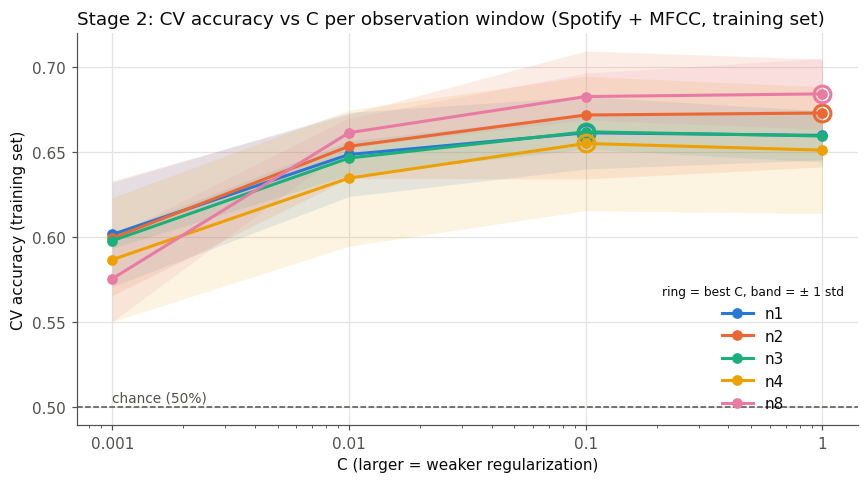

In [5]:
stage2 = {f"n{week}": run(load_dataset(week, "all"), FEATURE_SETS[BEST_FEATURES], desc=f"n{week}")
          for week in WEEKS}

print(f"Feature set: {BEST_FEATURES}")
print("CV accuracy on the training set (mean ± std) per C   (* = best C)")
display(curve_table({name: r["curve"] for name, r in stage2.items()}))
plot_c_curves({name: r["curve"] for name, r in stage2.items()},
              f"Stage 2: CV accuracy vs C per observation window ({BEST_FEATURES}, training set)")

,best C,CV accuracy,CV std,test accuracy,songs
scenario,,,,,
n1,0.1,0.6614,0.0213,0.6592,2448
n2,1,0.6730,0.0317,0.6728,2174
n3,0.1,0.6619,0.0102,0.6675,2030
n4,0.1,0.6551,0.0395,0.6816,1902
n8,1,0.6843,0.0209,0.6258,1588


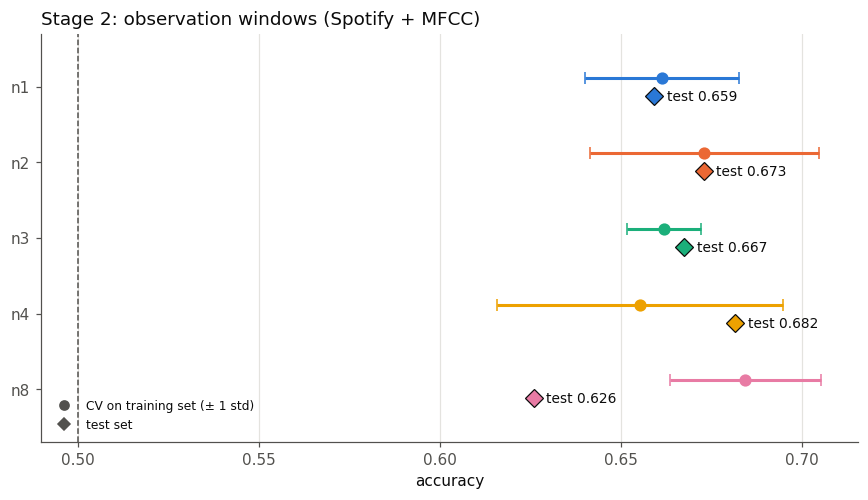

Best observation window (chosen by CV): n8  |  CV 0.6843, test 0.6258, C = 1


In [6]:
stage2_summary = summary_table(stage2, {f"n{w}": {"songs": len(load_dataset(w, "all"))} for w in WEEKS})
display(stage2_summary)
plot_results(stage2_summary, f"Stage 2: observation windows ({BEST_FEATURES})")

best_name = stage2_summary["CV accuracy"].idxmax()
BEST_WEEK = int(best_name.lstrip("n"))
print(f"Best observation window (chosen by CV): {best_name}  |  CV {stage2_summary.loc[best_name, 'CV accuracy']:.4f}, "
      f"test {stage2_summary.loc[best_name, 'test accuracy']:.4f}, C = {stage2_summary.loc[best_name, 'best C']}")

---
## Stage 3: Can old data still predict new data? (best week and feature set)

Old (released up to 2020) and new (from 2021) are each split 80:20.

* **Old → old**: tune C and train on old 80%, test on old 20%.
* **New → new**: tune C and train on new 80%, test on new 20%.
* **Old → new**: the old → old model (C tuned on old only), tested on the **same new 20%** as new → new.

Old → new and new → new are scored on exactly the same test songs, so their difference shows directly
how much is lost by training on old songs instead of recent ones.

Week n8, Spotify + MFCC: old train/test = 576/144, new train/test = 694/174



old:   0%|          | 0/4 [00:00<?, ?it/s]


old:  50%|█████     | 2/4 [00:00<00:00,  7.24it/s]


old:  75%|███████▌  | 3/4 [00:01<00:00,  1.83it/s]


old: 100%|██████████| 4/4 [00:09<00:00,  3.32s/it]


new:   0%|          | 0/4 [00:00<?, ?it/s]

... (2 outputs left out)


new:  75%|███████▌  | 3/4 [00:02<00:00,  1.11it/s]


new: 100%|██████████| 4/4 [00:11<00:00,  4.42s/it]

CV accuracy on each training set (mean ± std) per C   (* = best C)


,old (train 80%),new (train 80%)
C,,
0.001,0.528 ± 0.022,0.549 ± 0.027
0.01,0.613 ± 0.057,0.647 ± 0.057
0.1,0.625 ± 0.031,0.645 ± 0.038
1,0.634 ± 0.045 *,0.657 ± 0.035 *


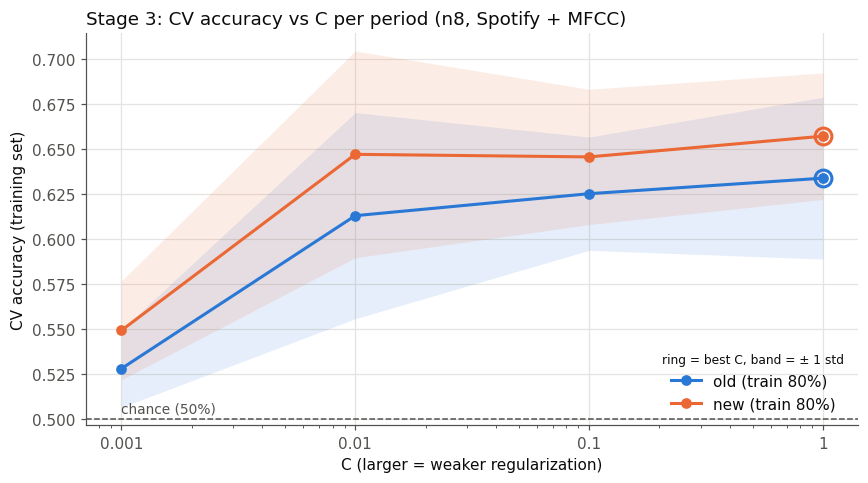

In [7]:
features = FEATURE_SETS[BEST_FEATURES]
X_old_tr, X_old_te, y_old_tr, y_old_te = split(load_dataset(BEST_WEEK, "old"), features)
X_new_tr, X_new_te, y_new_tr, y_new_te = split(load_dataset(BEST_WEEK, "new"), features)
print(f"Week n{BEST_WEEK}, {BEST_FEATURES}: old train/test = {len(y_old_tr)}/{len(y_old_te)}, "
      f"new train/test = {len(y_new_tr)}/{len(y_new_te)}")

old_old = tune_and_test(make_model, X_old_tr, y_old_tr, X_old_te, y_old_te, desc="old", C_grid=C_GRID_PEGASOS)
new_new = tune_and_test(make_model, X_new_tr, y_new_tr, X_new_te, y_new_te, desc="new", C_grid=C_GRID_PEGASOS)
pred_old_new = old_old["model"].predict(X_new_te)
old_new = {**old_old, "test_accuracy": check_accuracy(pred_old_new, y_new_te), "predictions": pred_old_new}

stage3 = {"Old → old": old_old, "New → new": new_new, "Old → new": old_new}
print("CV accuracy on each training set (mean ± std) per C   (* = best C)")
display(curve_table({"old (train 80%)": old_old["curve"], "new (train 80%)": new_new["curve"]}))
plot_c_curves({"old (train 80%)": old_old["curve"], "new (train 80%)": new_new["curve"]},
              f"Stage 3: CV accuracy vs C per period (n{BEST_WEEK}, {BEST_FEATURES})")

,best C,CV accuracy,CV std,test accuracy,train,test
scenario,,,,,,
Old → old,1,0.6337,0.0450,0.6667,old 80%,old 20%
New → new,1,0.6570,0.0352,0.7126,new 80%,new 20%
Old → new,1,0.6337,0.0450,0.6782,old 80%,new 20%


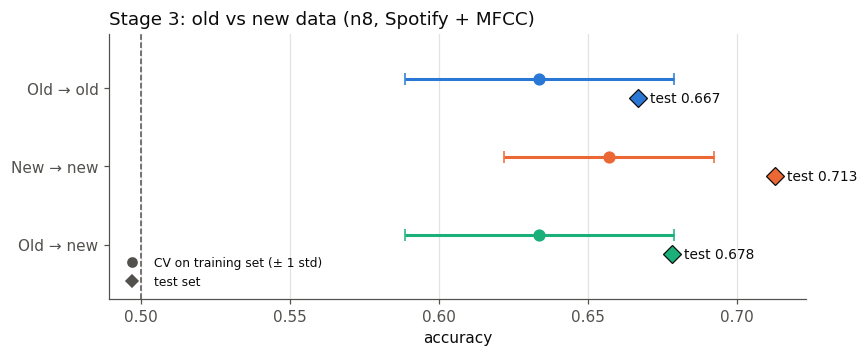

Confusion matrix: Old → new (new 20% test set)


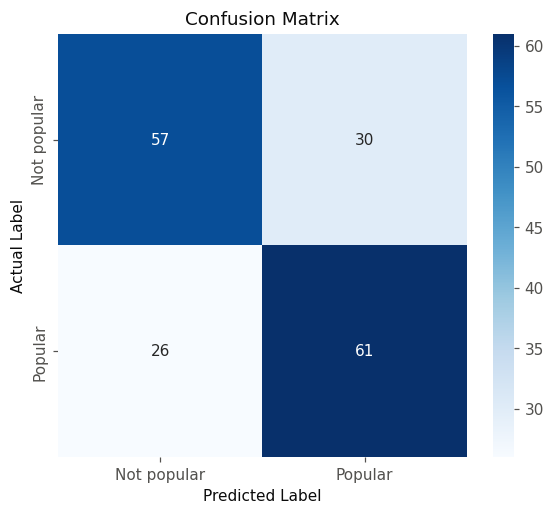

New → new minus old → new on the same 174 test songs: +0.0345 (+3.4 percentage points)


In [8]:
stage3_summary = summary_table(stage3, {
    "Old → old": {"train": "old 80%", "test": "old 20%"},
    "New → new": {"train": "new 80%", "test": "new 20%"},
    "Old → new": {"train": "old 80%", "test": "new 20%"},
})
display(stage3_summary)
plot_results(stage3_summary, f"Stage 3: old vs new data (n{BEST_WEEK}, {BEST_FEATURES})")

to_names = np.vectorize(LABEL_NAMES.get)
cm, labels = confusion_matrix(to_names(pred_old_new), to_names(y_new_te))
print("Confusion matrix: Old → new (new 20% test set)")
show_confusion_matrix(cm, labels)

gap = new_new["test_accuracy"] - old_new["test_accuracy"]
print(f"New → new minus old → new on the same {len(y_new_te)} test songs: {gap:+.4f} ({gap * 100:+.1f} percentage points)")

---
## Summary

In [9]:
print(f"Stage 1: best feature set        = {BEST_FEATURES}  (CV {stage1_summary.loc[BEST_FEATURES, 'CV accuracy']:.4f}, "
      f"test {stage1_summary.loc[BEST_FEATURES, 'test accuracy']:.4f})")
print(f"Stage 2: best observation window = n{BEST_WEEK}  (CV {stage2_summary.loc[f'n{BEST_WEEK}', 'CV accuracy']:.4f}, "
      f"test {stage2_summary.loc[f'n{BEST_WEEK}', 'test accuracy']:.4f})")
print(f"Stage 3 (test accuracy): old → new {old_new['test_accuracy']:.4f} | new → new {new_new['test_accuracy']:.4f} "
      f"| old → old {old_old['test_accuracy']:.4f}")

Stage 1: best feature set        = Spotify + MFCC  (CV 0.6614, test 0.6592)
Stage 2: best observation window = n8  (CV 0.6843, test 0.6258)
Stage 3 (test accuracy): old → new 0.6782 | new → new 0.7126 | old → old 0.6667


---
## Save the n8 model

Saves the Stage 2 n8 model (Spotify + MFCC, trained on the n8 80% training set with the CV-chosen C) to `models/`.
The `.json` next to it lists the feature columns in the order the model expects them, and `platt_a`,
the slope the web app uses to turn the SVM score into a confidence.

In [ ]:
import json
from model import save_model, load_model
from evaluation import fit_sigmoid_slope
from config import MODEL_FOLDER_PATH

n8 = stage2["n8"]
MODEL_NAME = "svm_n8_spotify_mfcc"
model_path = save_model(n8["model"], MODEL_NAME)

# Confidence for the web app: slope of a sigmoid on the SVM score, fitted on out-of-fold
# scores of the n8 training set (see evaluation.fit_sigmoid_slope)
X_tr8, X_te8, y_tr8, y_te8 = split(load_dataset(8, "all"), FEATURE_SETS[BEST_FEATURES])
platt_a = fit_sigmoid_slope(make_model, X_tr8, y_tr8, n8["best_C"])

meta = {"week": 8, "feature_set": BEST_FEATURES, "features": FEATURE_SETS[BEST_FEATURES],
        "C": n8["best_C"], "cv_accuracy": n8["cv_mean"], "cv_std": n8["cv_std"],
        "test_accuracy": n8["test_accuracy"], "labels": {str(k): v for k, v in LABEL_NAMES.items()}, "platt_a": platt_a}
with open(MODEL_FOLDER_PATH / f"{MODEL_NAME}.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

# check: the reloaded model gives the same test predictions
reloaded = load_model(MODEL_NAME)
assert (reloaded.predict(X_te8) == n8["predictions"]).all()
print(f"reloaded OK, test accuracy {check_accuracy(reloaded.predict(X_te8), y_te8):.4f}")